# Walmart vs Favorita: is the BUS→BS ensemble doing its job, and does pruning / size matter?
Reads the CSVs written by `walmart_cost_ensemble.ipynb` and `stores_cost_ensemble.ipynb`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 250)
datasets = ["walmart", "favorita"]
main = pd.concat([pd.read_csv(f"results/{d}_main.csv") for d in datasets])
dfd = pd.concat([pd.read_csv(f"results/{d}_dfd.csv") for d in datasets])
top = pd.concat([pd.read_csv(f"results/{d}_top_m2.csv") for d in datasets])
scaling = pd.concat([pd.read_csv(f"results/{d}_scaling.csv") for d in datasets])

display(main.groupby("dataset")[["N", "T"]].first())

,N,T
dataset,,
favorita,1100,956
walmart,2566,143


## 1. Search comparison per dataset and measure
`best_vs_BS` = best quality divided by unpruned BS's best. `evaluated_vs_BS` = quality computations
relative to unpruned BS (below 1 = cheaper).

In [2]:
reference = main[(main["method"] == "BS") & (~main["prune"])].set_index(["dataset", "measure"])
main["best_vs_BS"] = main.apply(lambda r: r["best"] / reference.loc[(r["dataset"], r["measure"]), "best"], axis=1)
main["evaluated_vs_BS"] = main.apply(lambda r: r["evaluated"] / reference.loc[(r["dataset"], r["measure"]), "evaluated"], axis=1)
main["runtime_vs_BS"] = main.apply(lambda r: r["runtime_s"] / reference.loc[(r["dataset"], r["measure"]), "runtime_s"], axis=1)

columns = ["runtime_s", "runtime_vs_BS", "evaluated", "evaluated_vs_BS", "pruned", "best_vs_BS",
           "jaccard_vs_BS", "shared_vs_BS", "avg_coverage", "pool_recall"]
for dataset in datasets:
    print(f"\n=== {dataset} ===")
    display(main[main["dataset"] == dataset].set_index(["measure", "method", "prune"])[columns].round(3))


=== walmart ===

=== favorita ===


runtime_s  runtime_vs_BS  ...  avg_coverage  pool_recall
measure method prune                            ...                           
M1      BS     False      0.614          1.000  ...         0.127          NaN
               True       0.672          1.094  ...         0.127          NaN
        BUS    False      0.999          1.626  ...         0.124          NaN
               True       0.606          0.986  ...         0.124          NaN
        BUS-α  False      0.934          1.521  ...         0.124          NaN
               True       0.787          1.282  ...         0.124          NaN
        BUS→BS False      0.497          0.809  ...         0.120        0.882
               True       0.568          0.925  ...         0.120        0.882
M2      BS     False      0.689          1.000  ...         0.129          NaN
               True       0.716          1.039  ...         0.129          NaN
        BUS    False      1.491          2.165  ...         0.127          NaN
               True       0.820          1.191  ...         0.127          NaN
        BUS-α  False      0.992          1.441  ...         0.127          NaN
               True       0.910          1.321  ...         0.127          NaN
        BUS→BS False      0.581          0.843  ...         0.123        0.875
               True       0.687          0.997  ...         0.123        0.875
M3      BS     False      1.538          1.000  ...         0.079          NaN
               True       1.599          1.040  ...         0.079          NaN
        BUS    False      3.370          2.191  ...         0.078          NaN
               True       3.066          1.993  ...         0.078          NaN
        BUS-α  False      3.449          2.242  ...         0.078          NaN
               True       3.217          2.092  ...         0.078          NaN
        BUS→BS False      1.319          0.857  ...         0.081        0.765
               True       1.351          0.878  ...         0.081        0.765

[24 rows x 10 columns]

runtime_s  runtime_vs_BS  ...  avg_coverage  pool_recall
measure method prune                            ...                           
M1      BS     False      0.278          1.000  ...         0.086          NaN
               True       0.231          0.829  ...         0.086          NaN
        BUS    False      0.049          0.175  ...         0.092          NaN
               True       0.040          0.143  ...         0.092          NaN
        BUS-α  False      0.061          0.219  ...         0.092          NaN
               True       0.057          0.206  ...         0.092          NaN
        BUS→BS False      0.137          0.493  ...         0.089        0.714
               True       0.133          0.477  ...         0.089        0.714
M2      BS     False      0.244          1.000  ...         0.092          NaN
               True       0.228          0.934  ...         0.092          NaN
        BUS    False      0.047          0.194  ...         0.097          NaN
               True       0.046          0.188  ...         0.097          NaN
        BUS-α  False      0.059          0.242  ...         0.097          NaN
               True       0.059          0.242  ...         0.097          NaN
        BUS→BS False      0.136          0.557  ...         0.090        0.688
               True       0.134          0.550  ...         0.090        0.688
M3      BS     False      0.246          1.000  ...         0.033          NaN
               True       0.235          0.952  ...         0.033          NaN
        BUS    False      0.178          0.724  ...         0.032          NaN
               True       0.364          1.477  ...         0.032          NaN
        BUS-α  False      0.320          1.300  ...         0.034          NaN
               True       0.201          0.815  ...         0.034          NaN
        BUS→BS False      0.188          0.765  ...         0.036        0.875
               True       0.179          0.726  ...         0.036        0.875

[24 rows x 10 columns]

## 2. Is the ensemble used properly?
Three checks for BUS→BS, per dataset and measure:
1. **pool_recall**: did the BUS voting keep the conditions that BS's best subgroups use?
2. **best_vs_BS / jaccard_vs_BS**: does restricting the beam to the pool lose quality or different subgroups?
3. **evaluated_vs_BS / runtime_vs_BS**: is it actually cheaper?

,dataset,measure,prune,pool_recall,best_vs_BS,jaccard_vs_BS,evaluated_vs_BS,runtime_vs_BS
6,walmart,M1,False,0.882,1.0,0.600,0.581,0.809
7,walmart,M1,True,0.882,1.0,0.600,0.561,0.925
14,walmart,M2,False,0.875,1.0,0.600,0.567,0.843
15,walmart,M2,True,0.875,1.0,0.600,0.553,0.997
22,walmart,M3,False,0.765,1.0,0.667,0.648,0.857
23,walmart,M3,True,0.765,1.0,0.667,0.490,0.878
6,favorita,M1,False,0.714,1.0,0.481,0.604,0.493
7,favorita,M1,True,0.714,1.0,0.481,0.560,0.477
14,favorita,M2,False,0.688,1.0,0.481,0.568,0.557
15,favorita,M2,True,0.688,1.0,0.481,0.564,0.550


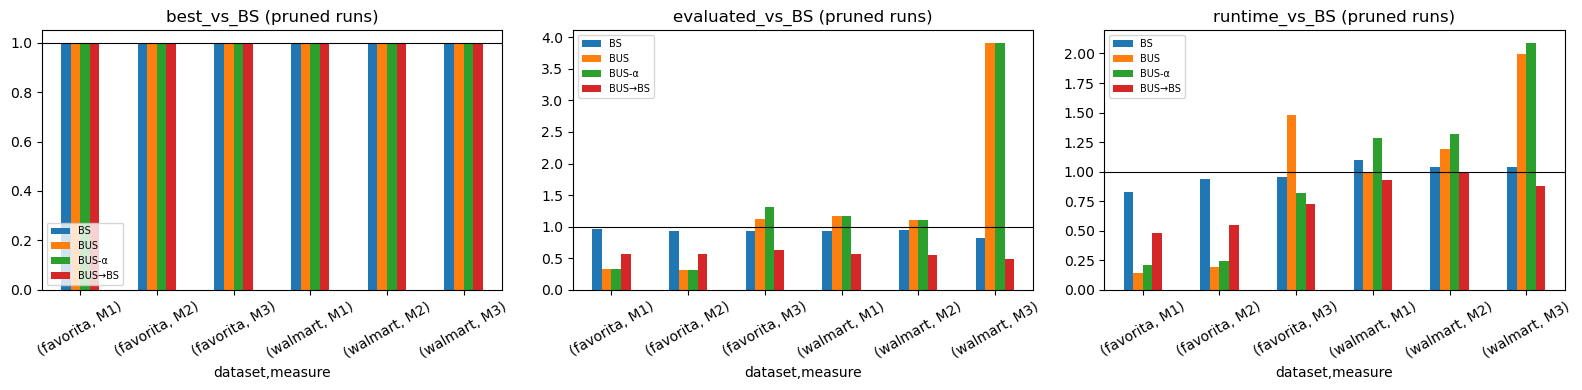

In [3]:
ensemble = main[main["method"] == "BUS→BS"][["dataset", "measure", "prune", "pool_recall", "best_vs_BS",
                                               "jaccard_vs_BS", "evaluated_vs_BS", "runtime_vs_BS"]]
display(ensemble.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ["best_vs_BS", "evaluated_vs_BS", "runtime_vs_BS"]):
    pivot = main[main["prune"]].pivot_table(index=["dataset", "measure"], columns="method", values=metric)
    pivot.plot.bar(ax=ax, rot=30)
    ax.axhline(1, color="black", lw=0.8)
    ax.set_title(f"{metric} (pruned runs)")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

## 3. What does pruning buy?
Per method: change in quality computations, runtime and best quality when pruning is switched on.

In [4]:
pivot = main.pivot_table(index=["dataset", "measure", "method"], columns="prune",
                         values=["evaluated", "runtime_s", "best"])
pruning = pd.DataFrame({
    "evaluated_saved_%": 100 * (1 - pivot[("evaluated", True)] / pivot[("evaluated", False)]),
    "runtime_saved_%": 100 * (1 - pivot[("runtime_s", True)] / pivot[("runtime_s", False)]),
    "best_change_%": 100 * (pivot[("best", True)] / pivot[("best", False)] - 1),
})
display(pruning.round(1))

evaluated_saved_%  runtime_saved_%  best_change_%
dataset  measure method                                                   
favorita M1      BS                    3.3             17.1            0.0
                 BUS                  16.7             18.6            0.0
                 BUS-α                16.7              5.9            0.0
                 BUS→BS                7.3              3.2            0.0
         M2      BS                    6.8              6.6            0.0
                 BUS                  16.7              2.7            0.0
                 BUS-α                16.7              0.1            0.0
                 BUS→BS                0.7              1.1            0.0
         M3      BS                    7.5              4.8            0.0
                 BUS                   0.0           -103.9            0.0
                 BUS-α                 0.0             37.3            0.0
                 BUS→BS                9.2              5.0            0.0
walmart  M1      BS                    6.4             -9.4            0.0
                 BUS                  34.3             39.4            0.0
                 BUS-α                34.2             15.8            0.0
                 BUS→BS                3.3            -14.4            0.0
         M2      BS                    4.7             -3.9            0.0
                 BUS                  34.7             45.0            0.0
                 BUS-α                34.6              8.3            0.0
                 BUS→BS                2.5            -18.2            0.0
         M3      BS                   17.9             -4.0            0.0
                 BUS                   0.0              9.0            0.0
                 BUS-α                 0.0              6.7            0.0
                 BUS→BS               24.5             -2.5            0.0

## 4. Significance (store-level permutation DFD, M2, pruned)

In [5]:
display(dfd.round(3))
display(top[top["p_value"] < 0.05].groupby(["dataset", "method"]).size().rename("significant subgroups").to_frame())
for dataset in datasets:
    print(f"\n=== {dataset}: BUS→BS top 10 ===")
    display(top[(top["dataset"] == dataset) & (top["method"] == "BUS→BS")].head(10).round(3))


=== walmart: BUS→BS top 10 ===

=== favorita: BUS→BS top 10 ===


,dataset,method,nu,dfd_seconds,dfd_median,dfd_95,best_quality,n_significant_005
0,walmart,BS,100,73.274,4.841174e+07,6.053017e+07,6.350184e+07,1
1,walmart,BUS,100,41.146,4.664079e+07,6.053017e+07,6.350184e+07,1
2,walmart,BUS-α,100,41.504,4.664079e+07,6.053017e+07,6.350184e+07,1
3,walmart,BUS→BS,100,40.816,4.615505e+07,5.953493e+07,6.350184e+07,1
0,favorita,BS,100,23.153,6.642338e+06,9.617263e+06,6.671463e+06,0
1,favorita,BUS,100,4.229,5.594327e+06,9.009286e+06,6.671463e+06,0
2,favorita,BUS-α,100,4.233,5.594327e+06,9.009286e+06,6.671463e+06,0
3,favorita,BUS→BS,100,14.919,5.992433e+06,9.464705e+06,6.671463e+06,0


significant subgroups
dataset method                       
walmart BS                          1
        BUS                         1
        BUS-α                       1
        BUS→BS                      1

,rank,description,excess_$,pct_of_normal,per_record_period,coverage_n,n_stores,method,p_value,dataset,excess_units
60,1,Temperature_volatility_cat = medium AND Fuel_P...,-6.350184e+07,-5.413,-1168.602,380,6,BUS→BS,0.040,walmart,NaN
61,2,Temperature_slope_cat = medium AND Unemploymen...,-5.953723e+07,-4.841,-1092.767,381,6,BUS→BS,0.059,walmart,NaN
62,3,Temperature_volatility_cat = medium AND Unempl...,-5.599170e+07,-6.743,-1553.771,252,4,BUS→BS,0.119,walmart,NaN
63,4,Temperature_volatility_cat = medium AND Unempl...,-5.470816e+07,-5.706,-1214.522,315,5,BUS→BS,0.158,walmart,NaN
64,5,Fuel_Price_slope_cat = high AND CPI_slope_cat ...,-5.400519e+07,-5.275,-1007.090,375,6,BUS→BS,0.168,walmart,NaN
65,6,Fuel_Price_volatility_cat = medium AND Size_ca...,-4.783757e+07,-3.756,-1001.582,334,5,BUS→BS,0.416,walmart,NaN
66,7,Type = A AND Temperature_volatility_cat = medi...,-4.718133e+07,-3.700,-926.796,356,6,BUS→BS,0.436,walmart,NaN
67,8,Fuel_Price_mean_cat = low AND CPI_volatility_c...,4.693787e+07,5.275,872.970,376,6,BUS→BS,0.446,walmart,NaN
68,9,Unemployment_slope_cat = high AND MarkDown_per...,-4.569024e+07,-3.872,-974.122,328,5,BUS→BS,0.525,walmart,NaN
69,10,Temperature_volatility_cat = medium AND Unempl...,-4.502701e+07,-3.638,-948.416,332,5,BUS→BS,0.545,walmart,NaN


,rank,description,excess_$,pct_of_normal,per_record_period,coverage_n,n_stores,method,p_value,dataset,excess_units
60,1,transactions_mean_cat = low AND transactions_s...,NaN,21.633,88.336,79,4,BUS→BS,0.396,favorita,6671462.647
61,2,type = D AND transactions_mean_cat = low,NaN,16.688,56.311,115,6,BUS→BS,0.455,favorita,6190882.514
62,3,transactions_slope_cat = high AND transactions...,NaN,7.578,48.386,125,6,BUS→BS,0.584,favorita,5782178.130
63,4,type = D AND transactions_slope_cat = high,NaN,11.650,58.335,83,4,BUS→BS,0.911,favorita,4628728.426
64,5,type = D AND transactions_mean_cat = low AND t...,NaN,34.582,116.521,40,2,BUS→BS,0.921,favorita,4455768.166
65,6,transactions_slope_cat = low AND transactions_...,NaN,-8.099,-35.045,129,7,BUS→BS,0.931,favorita,-4321917.635
66,7,transactions_mean_cat = low AND promo_mean_vs_...,NaN,9.197,36.372,123,22,BUS→BS,0.931,favorita,4276864.123
67,8,cluster = 6,NaN,6.156,35.450,125,6,BUS→BS,0.941,favorita,4236262.945
68,9,transactions_slope_cat = low AND promo_slope_v...,NaN,-8.179,-53.286,83,11,BUS→BS,0.941,favorita,-4228148.999
69,10,type = D AND transactions_volatility_cat = medium,NaN,10.800,51.614,84,4,BUS→BS,0.950,favorita,4144840.554


## 5. Scaling with the number of records
Mean over seeds. Solid = pruned, dotted = not pruned.

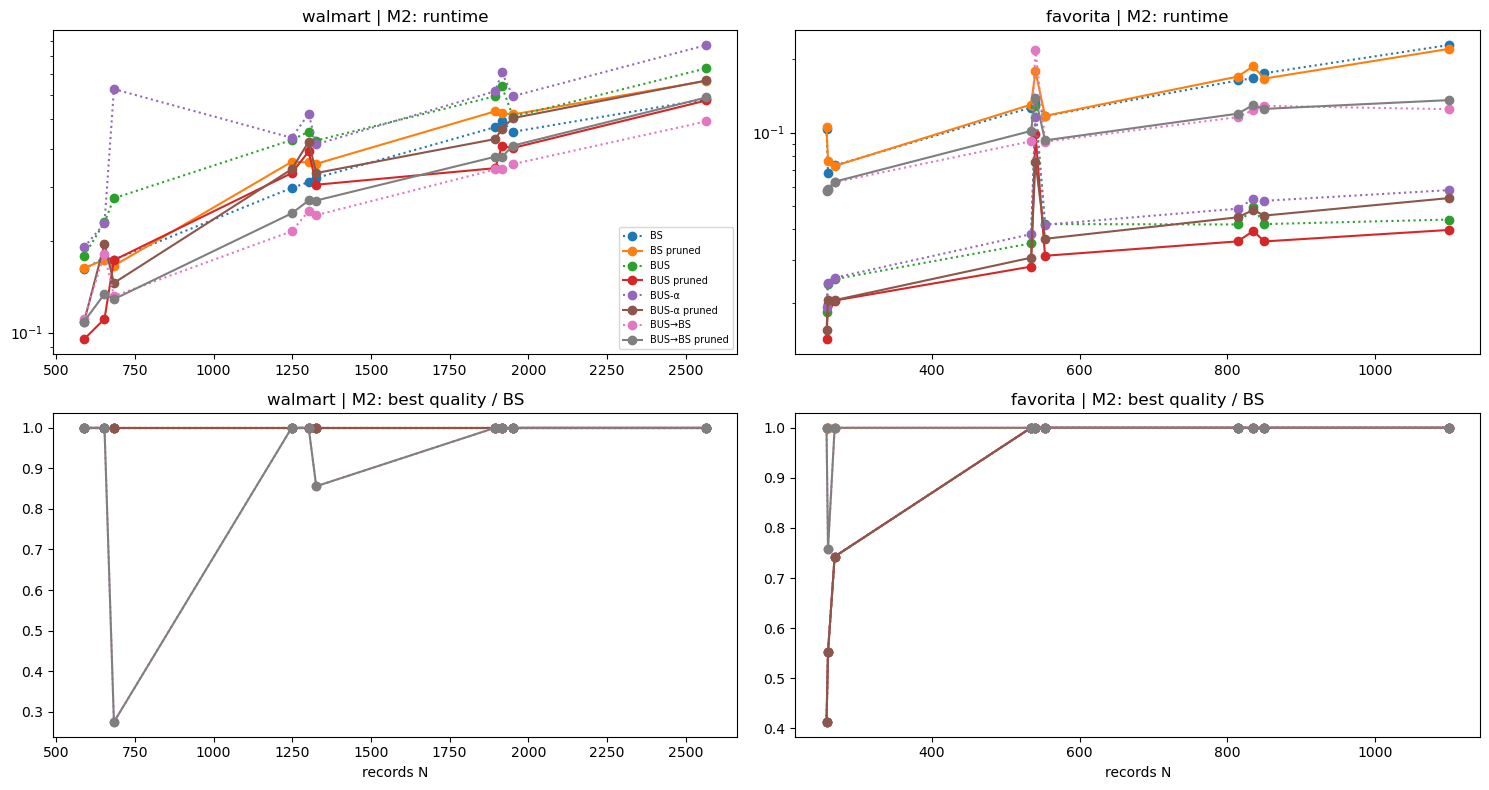

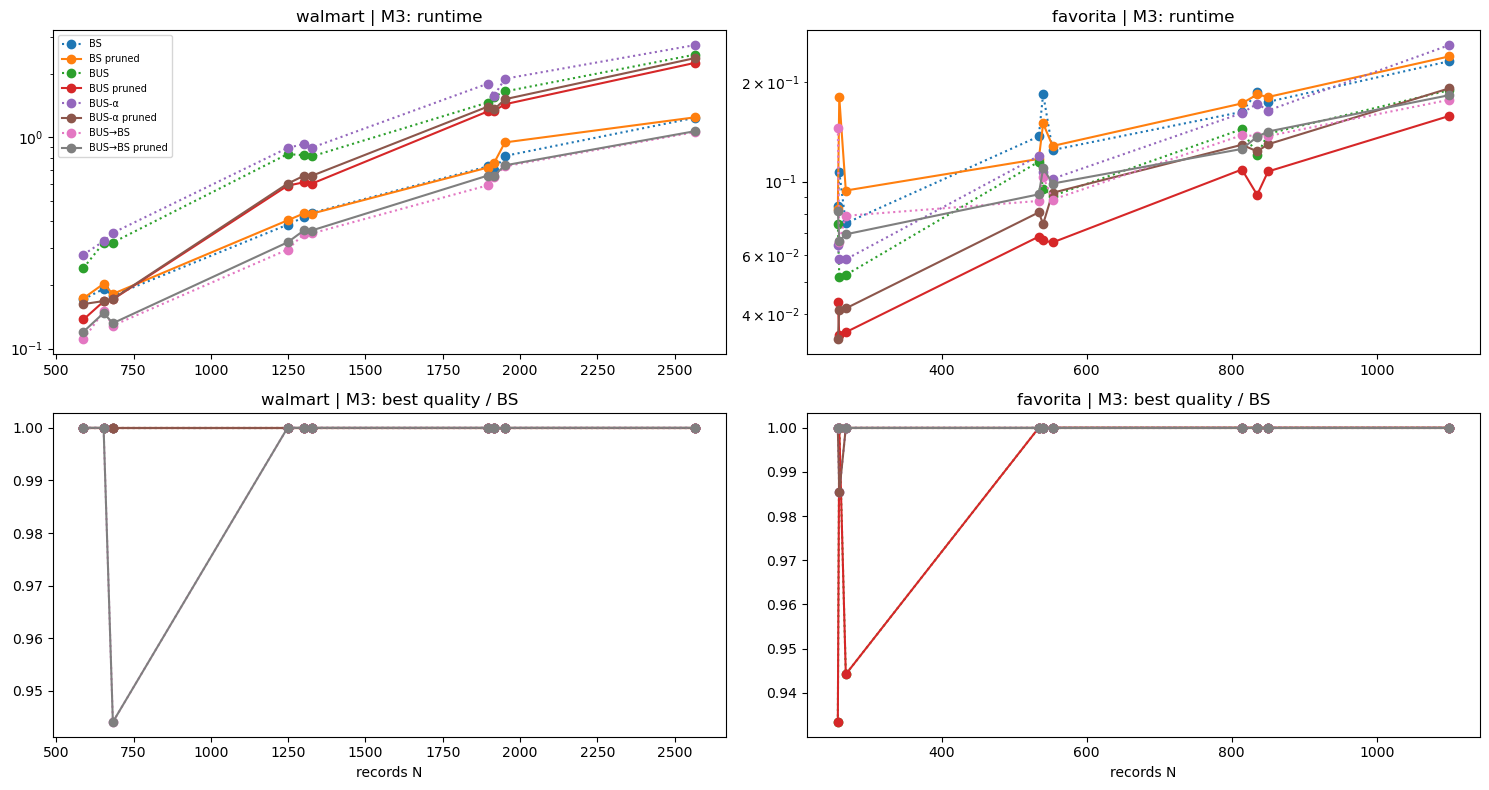

N_sub  ...  jaccard_vs_BS
dataset  measure method prune fraction            ...               
favorita M2      BS     False 0.25       261.333  ...          1.000
                              0.50       542.333  ...          1.000
                              0.75       833.000  ...          1.000
                              1.00      1100.000  ...          1.000
                        True  0.25       261.333  ...          1.000
...                                          ...  ...            ...
walmart  M3      BUS→BS False 1.00      2566.000  ...          0.667
                        True  0.25       641.333  ...          0.833
                              0.50      1292.000  ...          0.571
                              0.75      1920.667  ...          0.792
                              1.00      2566.000  ...          0.667

[128 rows x 5 columns]

In [6]:
for measure in ["M2", "M3"]:
    fig, axes = plt.subplots(2, 2, figsize=(15, 8))
    for col, dataset in enumerate(datasets):
        sub = scaling[(scaling["dataset"] == dataset) & (scaling["measure"] == measure)]
        agg = sub.groupby(["method", "prune", "N_sub"])[["runtime_s", "best_vs_BS"]].mean().reset_index()
        for (method, prune), g in agg.groupby(["method", "prune"]):
            style = "-" if prune else ":"
            axes[0, col].plot(g["N_sub"], g["runtime_s"], marker="o", ls=style, label=f"{method}{' pruned' if prune else ''}")
            axes[1, col].plot(g["N_sub"], g["best_vs_BS"], marker="o", ls=style, label=f"{method}{' pruned' if prune else ''}")
        axes[0, col].set_title(f"{dataset} | {measure}: runtime")
        axes[0, col].set_yscale("log")
        axes[1, col].set_title(f"{dataset} | {measure}: best quality / BS")
        axes[1, col].set_xlabel("records N")
    axes[0, 0].legend(fontsize=7)
    plt.tight_layout()
    plt.show()

display(scaling.groupby(["dataset", "measure", "method", "prune", "fraction"])[
    ["N_sub", "runtime_s", "evaluated", "best_vs_BS", "jaccard_vs_BS"]].mean().round(3))

## Conclusions (full run: ν = 100, 4 store fractions × 3 seeds)
1. **Same best subgroup everywhere.** On the full data, all four searches find BS's best subgroup for every measure on both datasets.
2. **The ensemble works as intended.** BUS→BS needs 49–69% of BS's quality evaluations (Walmart 55–65%, Favorita 56–69%). Pool recall is 0.69–0.88, so the BUS votes keep most conditions BS relies on. Its top-20 average is 92–100% of BS's, and it shares 13–18 of BS's 20 subgroups.
3. **Plain BUS / BUS-α depend on the descriptors.** On Walmart (store-level descriptors only) they evaluate 1.7–3.9× more than BS and are slower. On Favorita (promotion descriptors vary within a store) they are very fast but shallow: they share only 11 of BS's 20 subgroups on M1/M2, with an average quality of 0.87× BS. The ensemble closes part of that gap (13/20, 0.93×).
4. **Pruning is safe; the gains are uneven.** Exact pruning in BUS saves about 35% of evaluations for M1/M2 with identical results. In BS it saves 3–18% and sometimes costs runtime (computing the bound). For M3 there is no optimistic estimate, so BUS saves nothing and BS saves ~8–18% via redundancy/coverage pruning.
5. **Scaling with N.** From 25% to 100% of Walmart stores (N ≈ 640 → 2566), evaluations grow 2.2× for BS, 4.4× for BUS and only 1.6× for the ensemble. But on small subsets the ensemble sometimes misses BS's best (Walmart 25%: 0.76×, Favorita 25%: 0.92×): fewer records give fewer good pairs to vote.
6. **Target length T does not matter for the search.** Favorita's 956-day target only affects building the distance matrices once (~2 s); BS/BUS never touch the series afterwards.
7. **Significance.** Walmart: the best narrow subgroup (−$63.5M, −5.4%, 6 stores) has p = 0.04 for every method; rank 2 is borderline (p ≈ 0.06–0.07); the rest are not significant. Favorita: nothing is significant; its best effects are within the range random store groupings produce.
